In [1]:
from ultralytics import YOLO
from ariadne_amd import RobotController
import numpy as np
import cv2, sys, os

sys.path.append("../src/")
import ARUCO_ariadne as ar

import importlib
import copy, time, datetime
from IPython.display import clear_output
from scipy.spatial.transform import Rotation 
from math import atan2, cos, sin, sqrt, pi
import matplotlib.pyplot as plt

from pyModbusTCP.client import ModbusClient


SDK_VERSION: 1.15.3


In [2]:
import socket

pi_ip = "192.168.40.102"

def cut_remote(pi_ip):
    """
    Open socket communication with the Raspberry, send the command to activate the knife and close socket
    Parameters:
        pi_ip: IP of the Raspberry
    """
    client_socket = socket.socket(socket.AF_INET, socket.SOCK_STREAM)
    client_socket.connect((pi_ip, 65432))
    
    # Send a request for the cutting
    client_socket.sendall(b'CUT')
    
    client_socket.close()
    
    return None

In [3]:
#Robot controller initialization

parent_dir = os.path.dirname(os.getcwd())

robot = RobotController('UR10', config_file=parent_dir+"/src/robots_config.yaml", ask_colision=True, reduced_mode=False)

/home/miguel/HERMES/src/robots_config.yaml
ATTENTION: Reduced mode is not enabled


In [5]:
#Move to initial position for finding the IP of the camera based on an ARUCO marker

calib = [-170, -90, -90, -90, 90, 0]
robot.move_joints(calib, speed = 150, acc = 150)
calib_pos = robot.read_position()

robot.move_gripper(0)

aruco_dict_type = cv2.aruco.DICT_5X5_1000
robotcam = ar.ChooseCamaraIP(aruco_dict_type, cameraIP="192.168.40.102", robotcamID=42)

# Intrinsic camera matrix and distortion coefficients
calibration_matrix_path = "../src/calibration_matrix.npy"
distortion_coefficients_path = "../src/distortion_coefficients.npy"

k = np.load(calibration_matrix_path)
d = np.load(distortion_coefficients_path)

#Choose to callibrate again or use the saved callibration

calib_yn = input("Callibrate robot 2? y/n : ")

posesFilename = "../src/CalibratioPosesUR10.txt"

if calib_yn == 'y':
    arucoID = 42
    R_g2b, t_g2b, R_t2c, t_t2c = ar.runCalibration(calib_pos, robotcam, aruco_dict_type, arucoID, posesFilename, 
                                                   robot, k, d, show_images=False)
else:
    data = np.load("../src/CalibratioParamsUR10.npz", allow_pickle=True)
    R_g2b = data["R_g2b"]
    t_g2b = data["t_g2b"]
    R_t2c = data["R_t2c"]
    t_t2c = data["t_t2c"]
robot.move_joints(calib, speed = 150, acc = 150)

robot.relative_move_linear([0,0,0.2,0,0,0])
search_pos0 = robot.read_joints()
robot.relative_move_linear([0.2,0,0,0,0,0])
search_pos1 = robot.read_joints()
search_positions = [search_pos0, search_pos1]


16
42
Robot camera identified


Callibrate robot 2? y/n :  n


In [6]:
def compute_pixel_to_meter_ratio(aruco_corners, marker_length_meters):
    """
    Computes the pixel-to-meter conversion ratio based on an ArUco marker's detected corners.

    Parameters:
        aruco_corners (numpy.ndarray): The corners of the detected marker,
            expected shape is (1, 4, 2) as returned by cv2.aruco.detectMarkers.
        marker_length_meters (float): The known side length of the ArUco marker in meters.

    Returns:
        float: The conversion factor in meters per pixel. 
               Multiply pixel distances by this factor to convert to meters.
    """
    # Reshape the corners to a (4, 2) array
    pts = aruco_corners.reshape((4, 2))
    
    # Compute distances between consecutive corners
    d1 = np.linalg.norm(pts[0] - pts[1])
    d2 = np.linalg.norm(pts[1] - pts[2])
    d3 = np.linalg.norm(pts[2] - pts[3])
    d4 = np.linalg.norm(pts[3] - pts[0])
    
    # Average the distances to get the effective side length in pixels
    avg_pixel_side = (d1 + d2 + d3 + d4) / 4.0
    
    # Compute the conversion ratio: meters per pixel
    conversion_ratio = marker_length_meters / avg_pixel_side
    
    return conversion_ratio


def get_H_sample2cam(arucoID, frame, rvecs, tvecs, ids, corners, center):
    """
    Computes the homogeneous transformation matrix (4x4) from a sample (defined relative
    to the image center) to the camera coordinate system using an ArUco marker as reference.

    Parameters:
        arucoID (int): The ID of the target ArUco marker.
        frame (ndarray): The current image frame (used for dimensions).
        rvecs (ndarray): Rotation vectors of the detected markers.
        tvecs (ndarray): Translation vectors of the detected markers.
        ids (ndarray): Detected marker IDs.
        corners (list): List of detected marker corner points.
        center (ndarray): Pixel coordinates of the sample center in the image.

    Returns:
        H_sample2cam (ndarray): 4x4 homogeneous transformation matrix that maps
                                the sample position into the camera frame.
    """
    flat_ids = ids.flatten()
    
    # Find the index of the target ArUco marker
    for i in range(len(flat_ids)):
        if ids[i] == arucoID:
            index = i+1
            
    # Compute the marker's center in image coordinates (average of its corners)
    aruco_center = np.mean(corners[index-1], axis = 1)
    
    # Get image center (in pixels)
    img_h, img_w, channels = frame.shape
    image_center = np.array([img_w/2, img_h/2])
    
    # Accurate pixel-to-meter ratio from marker geometry
    pix_to_m = compute_pixel_to_meter_ratio(corners[index-1], 0.05)
    
    
    sample_pos = (center-image_center)*pix_to_m
    tvec_sample = copy.copy(tvecs[index])
    tvec_sample[0] = sample_pos[0]
    tvec_sample[1] = sample_pos[1]
    dst, jacobian = cv2.Rodrigues(rvecs[index])    # Convert rotation vector to rotation matrix
    H_sample2cam_3x4 = np.hstack((dst,np.reshape(tvec_sample, (3,1))))    # Build 3x4 extrinsic matrix [R | t]
    H_sample2cam = np.vstack((H_sample2cam_3x4, [0,0,0,1]))    # Convert to 4x4 homogeneous transformation matrix
    return H_sample2cam

def getSampleXYZ(arucoID, frame, rvecs, tvecs, ids, corners, center,R_g2b, t_g2b, R_t2c, t_t2c, pose):
    """
    Computes the 3D coordinates (X, Y, Z) of a sample in the robot base frame
    using an ArUco marker as a reference and known robot/camera calibration.

    Parameters:
        arucoID (int): ID of the target ArUco marker.
        frame (ndarray): Current camera image (used for dimensions).
        rvecs (ndarray): Rotation vectors of detected ArUco markers.
        tvecs (ndarray): Translation vectors of detected ArUco markers.
        ids (ndarray): Detected marker IDs.
        corners (list): List of detected marker corner coordinates.
        center (ndarray): Pixel coordinates of the sample in the image.
        R_g2b (ndarray): Rotation from gripper to robot base.
        t_g2b (ndarray): Translation from gripper to robot base.
        R_t2c (ndarray): Rotation from target to camera.
        t_t2c (ndarray): Translation from target to camera.
        pose (ndarray): Robot gripper pose [x, y, z, roll, pitch, yaw] in base frame.

    Returns:
        X, Y, Z (float): 3D coordinates of the sample in the robot base frame.
        H_target2base (ndarray): 4x4 homogeneous transformation of target→base.
    """
    pose_copy = copy.copy(pose)
    pose_copy[3] = np.radians(pose_copy[3])
    pose_copy[4] = np.radians(pose_copy[4])
    pose_copy[5] = np.radians(pose_copy[5])
    
    # Chain of transformations:
    H_cam2gripper = ar.get_H_cam2gripper(R_g2b, t_g2b, R_t2c, t_t2c)    
    H_sample2cam = get_H_sample2cam(arucoID, frame, rvecs, tvecs, ids, corners, center)     
    H_target2gripper = ar.get_H_target2gripper(H_cam2gripper, H_sample2cam)    
    H_gripper2base = ar.get_H_gripper2base(pose_copy)
    H_target2base = ar.get_H_target2base(H_gripper2base, H_target2gripper)
    
    X = H_target2base[0,3]
    Y = H_target2base[1,3]
    Z = H_target2base[2,3]
    
    return X, Y, Z, H_target2base

def find_center_and_angle(image, result, index=0, show = True):
    """
    Given an image and the results of YOLO segmentation, it finds the center of the specimen and its orientation.
    """

    #First, a mask is 
    polygon = result[0].masks.xy[index]

    mask = np.zeros((image.shape[0], image.shape[1]), dtype=np.uint8)
    cv2.fillPoly(mask, pts=[polygon.astype(int)], color=(255, 255, 255))
    
    pts = np.array([np.array([np.flip(i)]) for i in np.argwhere(mask>100)])
    sz = len(pts)
    data_pts = np.empty((sz, 2), dtype=np.float64)
    for i in range(data_pts.shape[0]):
        data_pts[i,0] = pts[i,0,0]
        data_pts[i,1] = pts[i,0,1]
    # Perform PCA analysis
    mean = np.empty((0))
    mean, eigenvectors, eigenvalues = cv2.PCACompute2(data_pts, mean)
    # Store the center of the object
    cntr = np.array([int(mean[0,0]), int(mean[0,1])])
    angle = atan2(eigenvectors[0,1], eigenvectors[0,0]) # orientation in radians

    if show == True:
        img = copy.copy(image)
        cv2.circle(img, cntr, 20, (255, 0, 0), 10)
        end_point = cntr+[100*np.cos(angle), 100*np.sin(angle)]
        cv2.arrowedLine(img, (cntr[0],cntr[1]), (int(end_point[0]),int(end_point[1])), (255, 0, 0), 10)
        plt.imshow(img)
        plt.show()

    return cntr, np.rad2deg(angle)

def pick_specimen(detection_joints, robot, robotcam, max_speed, max_acc, lin_speed, lin_acc):
    """
    Funtion to detect and pick the specimen
    """
    
    robot.move_joints(detection_joints, speed = max_speed, acc = max_acc)
    
    opening = 50
    robot.move_gripper(opening, force = 100)
    
    found = False
    
    # Loop for YOLO segmentation

    for i in range(1):
        if found == False:
    
            img = ar.get_latest_mjpeg_frame(robotcam)
            
            
            now = datetime.datetime.now()
            month = now.month
            day = now.day
            hour = now.hour
            minute = now.minute
            date = str(month)+"_"+str(day)+"_"+str(hour)+"_"+str(minute)

            #cv2.imwrite("images_to_train/image_"+date+".png", img)
            #cv2.imwrite(img_route+img_file+img_ext, img)
    
            model = YOLO("runs/segment/train/weights/best.pt")
            result = model.predict(source = img,
                                  imgsz = 640,
                                  conf = 0.1,
                                  save = False)
                                  #filename = "segmentation.png")
                                  #save_txt = True,
                                  #project = 'charpy2segment',
                                  #name = 'initial_tests',
                                  #save_conf = True,
                                  #exist_ok = True)
                                    
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
            confs = result[0].boxes.conf.cpu()
            labels = result[0].boxes.cls.cpu()
    
            if (1 in labels) and (0 in labels):
                found = True
            else:
                pose = robot.read_position()
                pose[2] += 0.1
                robot.go_to_position(pose, speed = lin_speed, acc = lin_acc)
                
    
                
    if (1 in labels) and (0 in labels):
        found = True
    else:
        found = False
    
    if found == True:
    
        index = np.argmax(np.where(labels==0, confs, 0))
    
        center, angle = find_center_and_angle(img, result, index, show=True)
        
        index_sprue = np.argmax(np.where(labels==1, confs, 0))
        center_s, angle_s = find_center_and_angle(img, result, index_sprue, show=True)
        
        angle_sprue = np.rad2deg(atan2((center_s[1]-center[1]),(center_s[0]-center[0])))
    
        """
        if abs(angle-angle_sprue)>90:
            if angle>90:
                angle-=1803.14
            elif angle<-90:
                angle+=180
        """
    
        if abs(angle-angle_sprue)>90:
            if angle>90:
                angle-=180
            elif angle<90:
                angle+=180
        #angle -= 180
        
        ARUCO_found = False
        
        while ARUCO_found == False:
        
            frame, rvecs, tvecs, ids, corners = ar.pose_estimation(img, aruco_dict_type, k, d, True)
        
            if ids is None:
                print("ArUco marker not found. Retrying...")
                img = ar.get_latest_mjpeg_frame(robotcam)
            else:
                ARUCO_found = True
    
        plt.imshow(frame)
        plt.show()
    
        pose = robot.read_position()
        X, Y, Z, H = getSampleXYZ(16, img, rvecs, tvecs, ids, corners, center,R_g2b, t_g2b, R_t2c, t_t2c, pose)
    
        pose = robot.read_position()
        pose[0] = X
        pose[1] = Y
        pose[2] = 0.11
        robot.go_to_position(pose, speed = lin_speed, acc = lin_acc)
    
        joints = robot.read_joints()
        joints[-1] = angle + copy.copy(joints[0]) - 90
        robot.move_joints(joints, speed = max_speed, acc = max_acc)
    
        robot.UntilContact(5, axis=2, sign=-1)
        robot.relative_move_linear([0,0,0.0005,0,0,0])
        robot.move_gripper(0, force = 20)
        
        robot.move_joints(detection_joints, speed = max_speed, acc = max_acc)

    else:
        print("Specimen not found, waiting for next injection")

    return found

def alignment(align_joints, robot, max_speed, max_acc, lin_speed, lin_acc):
    """
    Comands to use the sample aligner 
    """
    robot.move_joints(align_joints, speed = max_speed, acc = max_acc)
    robot.relative_move_linear([0,0,-0.045,0,0,0], speed = lin_speed, acc = lin_acc)
    
    pose = robot.read_position()
    robot.UntilContact(10, axis=1, sign=-1)
    robot.relative_move_linear([0,+0.03,0,0,0,0], speed = lin_speed, acc = lin_acc)
    
    #robot.relative_move_linear([0,+0.005,0,0,0,0], speed = lin_speed, acc = lin_acc)
    robot.move_gripper(30, force = 100)
    #robot.relative_move_linear([0,-0.009,0,0,0,0], speed = lin_speed, acc = lin_acc)

    pose[1] -= 0.005
    robot.go_to_position(pose, speed = lin_speed, acc = lin_acc)
    
    robot.relative_move_linear([0,0,-0.04,0,0,0], speed = lin_speed, acc = lin_acc)
    robot.move_gripper(0, force = 100)
    robot.relative_move_linear([0,0,+0.05,0,0,0], speed = lin_speed, acc = lin_acc)
    robot.move_gripper(30, force = 100)
    robot.move_gripper(30, force = 100)

    robot.relative_move_linear([0,0,-0.05,0,0,0], speed = lin_speed, acc = lin_acc)
    robot.relative_move_linear([0,0,-0.015,0,0,0], speed = lin_speed, acc = lin_acc)
    robot.move_gripper(0, force = 100)
    robot.relative_move_linear([0,-0.001,0,0,0,0], speed = lin_speed, acc = lin_acc)
    robot.move_joints(align_joints, speed = max_speed, acc = max_acc)
    
def cut_specimen(cut_joints, robot, pi_ip, max_speed, max_acc, lin_speed, lin_acc):
    """
    Movements to perform the cutting
    """
    robot.move_joints(cut_joints, speed = max_speed, acc = max_acc)
    robot.relative_move_linear([0,0,-0.04,0,0,0], speed = lin_speed, acc = lin_acc)
    robot.UntilContact(10, axis=0, sign=-1)
    robot.relative_move_linear([0.036,-0.012,0,0,0,0], speed = lin_speed, acc = lin_acc)
    cut_remote(pi_ip)
    robot.UntilContact(5, axis=2, sign=-1)
    robot.forceControl(-30, 2, 15)
    
    #robot.relative_move_linear([-0.005,0,0.005,0,0,0], speed = lin_speed, acc = lin_acc)

    #Sweep:
    robot.relative_move_linear([0,-0.005,0.03,0,0,0], speed = lin_speed, acc = lin_acc)
    robot.relative_move_linear([0,+0.02,0,0,0,0], speed = lin_speed, acc = lin_acc)
    

    robot.move_joints(cut_joints, speed = max_speed, acc = max_acc)
    
    

    robot.relative_move_linear([0,0,0.1,0,0,0], speed = lin_speed, acc = lin_acc)

    robot.relative_move_joints([30,0,0,0,0,0], speed = max_speed, acc = max_acc)
    robot.relative_move_joints([0,0,0,+40,0,0], speed = max_speed, acc = 10*max_acc)
    robot.relative_move_linear([0,0,-0.1,0,0,0], speed = lin_speed, acc = 5*lin_acc)
    
    robot.relative_move_linear([0,0,+0.1,0,0,0], speed = lin_speed, acc = 5*lin_acc)
    robot.relative_move_joints([0,0,0,-40,0,0], speed = max_speed, acc = 10*max_acc)
    robot.relative_move_joints([-30,0,0,0,0,0], speed = max_speed, acc = max_acc)
    
def leaveInTray(trayARUCO, slot, all_arucos_dict, robot, 
              robotcam, aruco_dict_type, k, d, origin,
              R_g2b, t_g2b, R_t2c, t_t2c, max_speed, max_acc, lin_speed, lin_acc):
    
    """
    Function to locate the tray and leave the specimen in the corresponding slot.
    """
    
    X, Y = all_arucos_dict[trayARUCO]
    pose = robot.read_position()
    pose[0] = X 
    pose[1] = Y 
    pose[2] = 0.25
    robot.go_to_position(pose, speed = lin_speed, acc = lin_acc)

    joints = copy.copy(robot.read_joints())
    joints[-1] = 0
    robot.move_joints(joints, speed = max_speed, acc = max_acc)
    
    pose = robot.read_position()
    pose[0] = X - 0.1*np.cos(np.radians(joints[0]))
    pose[1] = Y - 0.1*np.sin(np.radians(joints[0])) + 0.05
    pose[2] = 0.25
    robot.go_to_position(pose, speed = lin_speed, acc = lin_acc)

    #success, frame = initAndTakePhoto(robotcam)
    frame = ar.get_latest_mjpeg_frame(robotcam)

    
    pose = robot.read_position()
    output, rvecs, tvecs, ids = ar.pose_estimation(frame, aruco_dict_type, k, d)

    X, Y, Z, H = ar.getArucoXYZ(trayARUCO, rvecs, tvecs, ids, R_g2b, t_g2b, R_t2c, t_t2c, pose)

    pose = robot.read_position()
    pose[0] = X 
    pose[1] = Y 
    pose[2] = 0.15
    robot.go_to_position(pose, speed = lin_speed, acc = lin_acc)
    
    """
    init_pose = copy.copy(robot.read_position())
    init_pose[3:6] = copy.copy(origin[3:6])
    robot.go_to_position(init_pose, speed = 10, acc = 5)

    joints = robot.read_joints()
    joints[-1] = 180
    robot.move_joints(joints, speed = max_speed, acc = max_acc)
    
    X, Y, H, all_arucos_dict = ar.goToARUCO2(trayARUCO, all_arucos_dict, robot, 
              robotcam, aruco_dict_type, k, d, origin,
              R_g2b, t_g2b, R_t2c, t_t2c, save_image = True)
    """
    
    rotation_matrix = H[:3,:3]  #Just rotation matrix

    r =  Rotation.from_matrix(rotation_matrix)
    angles = r.as_euler("xyz",degrees=True)

    joints = robot.read_joints()
    joints[-1] = joints[0]  - 180 - angles[2]
    while joints[-1] > 90:
        joints[-1] += - 180
    while joints[-1] < -90:
        joints[-1] += 180
    robot.move_joints(joints, speed = max_speed, acc = max_acc)
    
    tray_pose = copy.copy(robot.read_position())
    tray_pose[2] += 0.02
    robot.go_to_position(tray_pose, speed = lin_speed, acc = lin_acc)
    
    if slot < 8:
        position_in_tray_xy = [0.0225,-0.065-0.025*slot]
    else:
        position_in_tray_xy = [0.1275,0.01-0.025*(slot-8)]
    
    abs_position = [position_in_tray_xy[0] * np.cos(np.radians(angles[2])) - position_in_tray_xy[1] * np.sin(np.radians(angles[2])),
                           position_in_tray_xy[0] * np.sin(np.radians(angles[2])) + position_in_tray_xy[1] * np.cos(np.radians(angles[2]))]
            
    pose = copy.copy(tray_pose)
    pose[0] += abs_position[0]
    pose[1] += abs_position[1]
    robot.go_to_position(pose, speed = lin_speed, acc = lin_acc)

    Z = H[2,3]
    
    pose = robot.read_position()
    pose[2] = Z + 0.005
    robot.go_to_position(pose, speed = lin_speed, acc = lin_acc)
    
    robot.move_gripper(20, force = 100)
    time.sleep(1)
    
    pose = robot.read_position()
    pose[2] += 0.03
    robot.go_to_position(pose, speed = lin_speed, acc = lin_acc)
    
    robot.move_gripper(0, force = 100)
    
    joints = robot.read_joints()
    joints[-1] = 0
    robot.move_joints(joints, speed = max_speed, acc = max_acc)

    
    return all_arucos_dict

def take_tray(trayARUCO, all_arucos_dict, robot, 
              robotcam, aruco_dict_type, k, d, origin,
              R_g2b, t_g2b, R_t2c, t_t2c, trays_deposited,
             max_speed, max_acc, lin_speed, lin_acc, tray_deposit):
    """
    Function to locate the completed tray and move to deposit.
    """
    
    X, Y = all_arucos_dict[trayARUCO]
    pose = robot.read_position()
    pose[0] = X 
    pose[1] = Y 
    pose[2] = 0.25
    robot.go_to_position(pose, speed = lin_speed, acc = lin_acc)

    joints = copy.copy(robot.read_joints())
    joints[-1] = 0
    robot.move_joints(joints, speed = max_speed, acc = max_acc)
    
    pose = robot.read_position()
    pose[0] = X - 0.1*np.cos(np.radians(joints[0]))
    pose[1] = Y - 0.1*np.sin(np.radians(joints[0])) + 0.05
    pose[2] = 0.25
    robot.go_to_position(pose, speed = lin_speed, acc = lin_acc)

    #success, frame = initAndTakePhoto(robotcam)
    frame = ar.get_latest_mjpeg_frame(robotcam)

    
    pose = robot.read_position()
    output, rvecs, tvecs, ids = ar.pose_estimation(frame, aruco_dict_type, k, d)

    X, Y, Z, H = ar.getArucoXYZ(trayARUCO, rvecs, tvecs, ids, R_g2b, t_g2b, R_t2c, t_t2c, pose)

    pose = robot.read_position()
    pose[0] = X 
    pose[1] = Y 
    pose[2] = 0.15
    robot.go_to_position(pose, speed = lin_speed, acc = lin_acc)

    rotation_matrix = H[:3,:3]  #Just rotation matrix

    r =  Rotation.from_matrix(rotation_matrix)
    angles = r.as_euler("xyz",degrees=True)

    joints = robot.read_joints()
    joints[-1] = joints[0]  - 180 - angles[2]
    while joints[-1] > 90:
        joints[-1] += - 180
    while joints[-1] < -90:
        joints[-1] += 180
    robot.move_joints(joints, speed = max_speed, acc = max_acc)
    
    tray_pose = copy.copy(robot.read_position())
    tray_pose[2] += 0.02
    robot.go_to_position(tray_pose, speed = lin_speed, acc = lin_acc)
        
    position_in_tray_xy = [0.055, 0]
    
    abs_position = [position_in_tray_xy[0] * np.cos(np.radians(angles[2])) - position_in_tray_xy[1] * np.sin(np.radians(angles[2])),
                           position_in_tray_xy[0] * np.sin(np.radians(angles[2])) + position_in_tray_xy[1] * np.cos(np.radians(angles[2]))]
            
    Z = H[2,3]
    
    pose = copy.copy(tray_pose)
    pose[0] += abs_position[0]
    pose[1] += abs_position[1]
    pose[2] = Z+0.02
    robot.go_to_position(pose, speed = lin_speed, acc = lin_acc)

    
    
    robot.move_gripper(35, force = 100)
    
    
    """
    X, Y, H, all_arucos_dict = ar.fineArucoPosition(current_tray, all_arucos_dict, robot, 
              robotcam, aruco_dict_type, k, d, 
              R_g2b, t_g2b, R_t2c, t_t2c)

    pose = robot.read_position()
    pose[0] = X
    pose[1] = Y
    robot.go_to_position(pose)

    Z = H[2,3]
    
    tray_pose = copy.copy(robot.read_position())
    tray_pose[2] += 0.02
    robot.go_to_position(tray_pose)
        
    position_in_tray_xy = [0.055, 0]
    
    abs_position = [position_in_tray_xy[0] * np.cos(np.radians(angles[2])) - position_in_tray_xy[1] * np.sin(np.radians(angles[2])),
                           position_in_tray_xy[0] * np.sin(np.radians(angles[2])) + position_in_tray_xy[1] * np.cos(np.radians(angles[2]))]
            
    """
    pose = robot.read_position()
    pose[2] = Z - 0.02
    robot.go_to_position(pose, speed = 0.02)
    
    robot.move_gripper(0, force = 100)
    
    pose = robot.read_position()
    pose[2] = Z + 0.3
    robot.go_to_position(pose, speed = lin_speed, acc = lin_acc)

    
    
    #robot.relative_move_linear([0,0.25,0,0,0,0])
    
    robot.move_joints(tray_deposit, speed = max_speed, acc = max_acc)

    pose = robot.read_position()
    pose[0] += -0.05
    pose[2] = 0.01 + 0.02 * trays_deposited
    robot.go_to_position(pose, speed = lin_speed, acc = lin_acc)
    
    robot.move_gripper(32, force = 100)
    
    robot.relative_move_linear([0,0,0.2,0,0,0], speed = lin_speed, acc = lin_acc)
    
    return all_arucos_dict
 
def detect_new_tray(current_tray, all_arucos_dict, robot,
                   robotcam, aruco_dict_type, k, d, lin_speed, lin_acc):
    """
    Find the identity of the new tray
    """
    
    X, Y = all_arucos_dict[current_tray]
    angle = np.degrees(np.arctan2(Y,X))


    joints = copy.copy(robot.read_joints())
    joints[-1] = 0
    joints[0] = joints[0] + ((angle - joints[0] + 180) % 360 - 180)
    robot.move_joints(joints, speed = 100)

    pose = robot.read_position()
    pose[0] = X - 0.1*np.cos(np.radians(joints[0]))
    pose[1] = Y - 0.1*np.sin(np.radians(joints[0]))
    pose[2] = 0.25
    robot.go_to_position(pose, speed = lin_speed, acc = lin_acc)

    time.sleep(2)
    
    frame = ar.get_latest_mjpeg_frame(robotcam)

    pose = robot.read_position()
    output, rvecs, tvecs, ids = ar.pose_estimation(frame, aruco_dict_type, k, d)
    
    for id_ in ids:
        if id_[0] not in all_arucos_dict.keys():
            new_tray = id_[0]
            all_arucos_dict[new_tray] = X, Y
            
    return new_tray, all_arucos_dict

def detect_if_cut(second_detect, robot, robotcam, max_speed, max_acc):
    """
    YOLO verification of cutting success by detecting if sprue is still present.
    """
    robot.move_joints(second_detect, speed = max_speed, acc = max_acc)
    
    img = ar.get_latest_mjpeg_frame(robotcam)
    #cv2.imwrite("last_image.png", img)

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    now = datetime.datetime.now()
    month = now.month
    day = now.day
    hour = now.hour
    minute = now.minute
    date = str(month)+"_"+str(day)+"_"+str(hour)+"_"+str(minute)

    #cv2.imwrite("verification_images/image_"+date+"_after.png", img)

    model = YOLO("runs/detect/train2/weights/best.pt")
    result = model.predict(source = img,
                          imgsz = 640,
                          conf = 0.3,
                          save = False)
                          #filename = "segmentation.png")
                          #save_txt = True,
                          #project = 'charpy2segment',
                          #name = 'initial_tests',
                          #save_conf = True,
                          #exist_ok = True)
                            
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    confs = result[0].boxes.conf.cpu()
    labels = result[0].boxes.cls.cpu()
    
    error_detected = False
    
    if (0 in labels):
        plt.imshow(img)
        plt.savefig("last_image.png")
        plt.show()
        
        print("Error cutting, retrying...")
        error_detected = True
    return error_detected

def detect_if_picked(second_detect, robot, robotcam, max_speed, max_acc):
    
    """
    YOLO verification of picking success by detecting if sprue is visible by the camera.
    """
    robot.move_joints(second_detect, speed = max_speed, acc = max_acc)
    
    img = ar.get_latest_mjpeg_frame(robotcam)

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    now = datetime.datetime.now()
    month = now.month
    day = now.day
    hour = now.hour
    minute = now.minute
    date = str(month)+"_"+str(day)+"_"+str(hour)+"_"+str(minute)

    #cv2.imwrite("verification_images/image_"+date+"_before.png", img)

    model = YOLO("runs/detect/train2/weights/best.pt")
    result = model.predict(source = img,
                          imgsz = 640,
                          conf = 0.3,
                          save = False)
                            
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    confs = result[0].boxes.conf.cpu()
    labels = result[0].boxes.cls.cpu()
    
    error_detected = False
    
    if (0 not in labels):
        plt.imshow(img)
        plt.savefig("last_image.png")
        plt.show()
        print("Error picking, retrying...")
        error_detected = True
    return error_detected

In [11]:
# Connect to the injector
client = ModbusClient(host="192.168.40.20", auto_open=True, auto_close=True)

import requests

def wait_for_injector(client):
    print("Waiting for injector...")
    waiting = True
    start_time = time.time()
    timeout=600
    
    while waiting == True:
        time.sleep(0.1)

        if time.time() - start_time >= timeout:
            input("⚠️ No signal detected for 10 minutes. Press Enter when the problem is solved: ")
            send_telegram_message("Injector is not producing parts, assistance required!!!")
            
        regs = client.read_holding_registers(14, 1)
    
        if regs:
            if format(regs[0], '016b')[-4]=='1':
                print(regs[0])
                print('Part ready')
                time.sleep(1)
                waiting = False
        else:
            print("read error")

def log_to_file(file, msg):
    local_time = time.localtime(time.time())
    
    # Format as a readable string
    readable_time = time.strftime("%Y-%m-%d %H:%M:%S", local_time)

    text_to_append = f"{readable_time} : {msg}  \n"

    with open(file, "a") as file:
        file.write(text_to_append) 
        
TOKEN = "your_telegram_token"
CHAT_ID = "your_telegram_chat_id""

def send_telegram_message(text):
    """Send a message to Telegram."""
    url = f"https://api.telegram.org/bot{TOKEN}/sendMessage"
    payload = {"chat_id": CHAT_ID, "text": text}
    requests.post(url, data=payload)

def send_telegram_image(image_path):
    url = f"https://api.telegram.org/bot{TOKEN}/sendPhoto"
    # Open the image file in binary mode
    with open(image_path, "rb") as image_file:
        files = {"photo": image_file}
        data = {"chat_id": CHAT_ID}
        response = requests.post(url, files=files, data=data)
    return response.json()


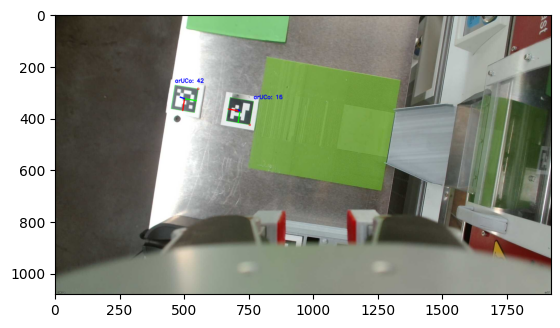

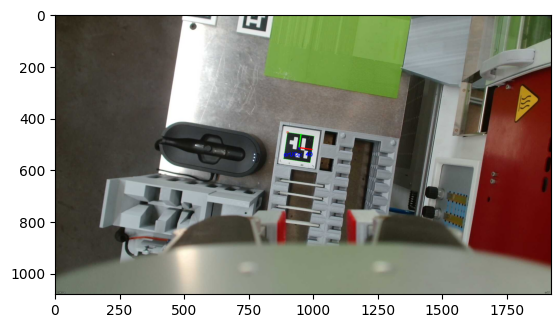

KeyboardInterrupt: 

In [15]:
number_of_trays = 5
tray_capacity = 19
first_tray = 40

max_speed = 150
max_acc = 150

lin_speed = 3
lin_acc = 1

all_arucos_dict = ar.findAllARUCOS(search_positions, calib_pos, robotcam, aruco_dict_type, robot, k, d, R_g2b, t_g2b, R_t2c, t_t2c, show_images = True)

detection_joints = [-164.73, -97.37, -103.11, -69.79, 90.01, 13.65]

align_joints = [-132.21, -66.00, -126.85, -75.85, 91.51, 138.59]

cut_joints = [-144.95, -57.08, -133.64, -78.33, 91.68, 217.33]

discard_joints = [-142.70, -104.60, -94.30, -71.48, 90.14, 35.67]

second_detect = [-166.44, -136.45, -60.69, -72.13, 89.16, -72.03]

tray_deposit = [-175.52, -117.08, -70.18, -80.61, 89.67, 95.897]


trays_deposited = 0

current_tray = first_tray
discard = False

local_time = time.localtime(time.time())
    
# Format as a readable string
readable_time = time.strftime("%Y-%m-%d %H:%M:%S", local_time)

output_file = f"../data/robot_logs/RobotCut_{readable_time}.txt"
log_to_file(output_file, "Starting experimental run.")
send_telegram_message("Starting experimental run.")


while trays_deposited < number_of_trays:
    slot = 0
    while slot < tray_capacity:

        log_to_file(output_file, "###### Cutting specimen " + str(slot) + " for tray " + str(current_tray) + "######")
        
        clear_output(wait=True)
        
        #wait_for_injector(client)
        
        wait = input("Press Enter")
        time.sleep(5)
        
        

        found = pick_specimen(detection_joints, robot, robotcam, max_speed, max_acc, lin_speed, lin_acc)

        if found:

            error_detected = detect_if_picked(second_detect, robot, robotcam, max_speed, max_acc)
    
            if error_detected:
                discard = True

                pick_specimen(detection_joints, robot, robotcam, max_speed, max_acc, lin_speed, lin_acc)
                log_to_file(output_file, "Error when picking, trying again...")
                #send_telegram_message("Error when picking, trying again...")
                error_detected = detect_if_picked(second_detect, robot, robotcam, max_speed, max_acc)
                while error_detected:
                    log_to_file(output_file, "Repeated error when picking, assistance needed!!!!!")
                    send_telegram_message("Repeated error when picking, assistance needed!!!!!")
                    send_telegram_image("last_image.png")
                    wait = input("Repeated error when picking, place the specimen in a visible area and press Enter:")
                    pick_specimen(detection_joints, robot, robotcam, max_speed, max_acc, lin_speed, lin_acc)
                    error_detected = detect_if_picked(second_detect, robot, robotcam, max_speed, max_acc)
    
            #robot.move_joints(calib, speed =100, acc = 100)
            robot.relative_move_linear([0,0,0.15,0,0,0], speed = lin_speed, acc = lin_acc, motion_type=1)
    
            alignment(align_joints, robot, max_speed, max_acc, lin_speed, lin_acc)
    
            cut_specimen(cut_joints, robot, pi_ip, max_speed, max_acc, lin_speed, lin_acc)
    
            error_detected = detect_if_cut(second_detect, robot, robotcam, max_speed, max_acc)
            if error_detected:
                alignment(align_joints, robot, max_speed, max_acc, lin_speed, lin_acc)
    
                cut_specimen(cut_joints, robot, pi_ip, max_speed, max_acc, lin_speed, lin_acc)
                log_to_file(output_file, "Error when cutting, trying again...")
                send_telegram_message("Error when cutting, trying again...")
                send_telegram_image("last_image.png")
                error_detected = detect_if_cut(second_detect, robot, robotcam, max_speed, max_acc)
                if error_detected:
                    robot.move_joints(discard_joints, speed=max_speed, acc = max_acc)
                    robot.move_gripper(35, force = 100)
                    slot -= 1
                discard = True
    
            all_arucos_dict = leaveInTray(current_tray, slot, all_arucos_dict, robot, 
                          robotcam, aruco_dict_type, k, d, calib_pos,
                          R_g2b, t_g2b, R_t2c, t_t2c, max_speed, max_acc, lin_speed, lin_acc)
    
            if discard == True:
                pick_specimen(detection_joints, robot, robotcam, max_speed, max_acc, lin_speed, lin_acc)
                if found:
                    robot.move_joints(discard_joints, speed=max_speed, acc = max_acc)
                    robot.move_gripper(35, force = 100)
                discard = False

            slot += 1
        else:
            log_to_file(output_file, "Specimen not found, out of bounds. Waiting for new ejection...")
            send_telegram_message("Specimen not found, out of bounds. Waiting for new ejection...")
        
    take_tray(current_tray, all_arucos_dict, robot, 
              robotcam, aruco_dict_type, k, d, calib_pos,
              R_g2b, t_g2b, R_t2c, t_t2c, trays_deposited,
              max_speed, max_acc, lin_speed, lin_acc, tray_deposit)
    
    trays_deposited += 1
    new_tray, all_arucos_dict = detect_new_tray(current_tray, all_arucos_dict, robot, robotcam, aruco_dict_type, k, d, lin_speed, lin_acc)
    current_tray = new_tray

    found = pick_specimen(detection_joints, robot, robotcam, max_speed, max_acc, lin_speed, lin_acc)
    if found:
        robot.move_joints(discard_joints, speed=max_speed, acc = max_acc)
        robot.move_gripper(35, force = 100)